# Recipe: Temperature-dependent optical constants

The three crystal axes of forsterite are three components, each with five temperature sets (files data/optical_constants/suto2006/fo_suto2006_<axis>_<T>K.dat, tdep = .true.). Every grain takes the set nearest to its own temperature ('nearest') or n, k interpolated in temperature ('linear'). Compared with the 295 K set alone, the 69 micron band of cold grains is narrower and moves to shorter wavelength.

**Files:** `data/optical_constants/suto2006/`  
**Run time:** about 35 s  
**Manual:** Sect. 16.9 of `docs/manual/dms_manual.pdf`. The same code as a script: `python3 examples/recipes/forsterite_temperature.py`.

In [1]:
# Setup: this notebook lives in examples/recipes/ of the repository
import os, sys
if "REPO" not in globals():
    REPO = os.environ.get("DMS_REPO") or os.path.abspath(os.path.join("..", ".."))
sys.path.insert(0, os.path.join(REPO, "python"))      # use the DMS of this repository
os.chdir(REPO)                                        # input files and cache/ are relative to the root
import dms
import numpy as np
import matplotlib.pyplot as plt
print("DMS", dms.__version__)

DMS 2.2.1


295 K only  peak of the band at 69.53 micron;  temperature range 48-87 K; 3 species


nearest     peak of the band at 68.83 micron;  temperature range 57-89 K; 15 species


linear      peak of the band at 68.83 micron;  temperature range 56-89 K; 78 species


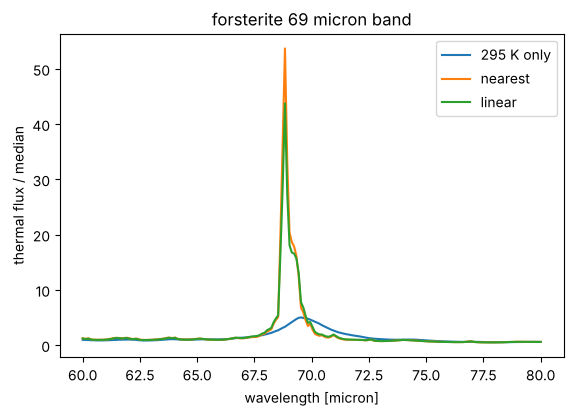

In [2]:
axes = ("A", "B", "C")
base = dms.Model(
    run={"mode": "sed", "emission": "thermal"},
    star={"teff": 8590.0, "radius": 1.84, "mass": 1.92, "distance": 20.0},
    disk={"r_in": 30.0, "r_out": 60.0, "dust_mass": 1e-8},
    wavelengths={"lambda_min": 60.0, "lambda_max": 80.0, "n_lambda": 200},
    dust={"n_components": 3, "bulk_density": [3.3] * 3, "abundance": [1.0] * 3,
          "a_min": 1.0, "a_max": 30.0, "q": 3.5, "n_sizes": 40})
cases = {
    "295 K only": {"optical_data": [f"suto2006/fo_suto2006_{x}_295K.dat" for x in axes]},
    "nearest": {"optical_data": [f"suto2006/fo_suto2006_{x}" for x in axes], "tdep": [True] * 3,
                "tdep_mode": "nearest"},
    "linear": {"optical_data": [f"suto2006/fo_suto2006_{x}" for x in axes], "tdep": [True] * 3,
               "tdep_mode": "linear", "tdep_dt": 10.0},
}
fig, ax = plt.subplots(figsize=(6.5, 4.2))
for label, dust in cases.items():
    r = base.copy().update(dust=dust).run()
    lam, f = r.wavelength, r.sed["thermal"]
    print(f"{label:10s}  peak of the band at {lam[np.argmax(f)]:.2f} micron;  "
          f"temperature range {r.temperature['T'].min():.0f}-{r.temperature['T'].max():.0f} K; "
          f"{len(r.species['T'])} species")
    ax.plot(lam, f / np.median(f), label=label)
ax.set_xlabel("wavelength [micron]"); ax.set_ylabel("thermal flux / median")
ax.set_title("forsterite 69 micron band"); ax.legend()
plt.show()

**Result.** The grains are at 56–89 K. With the optical constants at their temperature the 69 µm band is narrower and stronger and peaks at 68.8 µm, against 69.5 µm with the 295 K set alone. `'nearest'` uses 15 data sets; `'linear'` makes 78 species with steps of at most 10 K.